<a href="https://colab.research.google.com/github/ade071212/Tugas-Modul-ML/blob/main/Tugas_Modul_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
#1. Muat Data

In [ ]:
# Membuat dataset sintetis 1000 mahasiswa (ganti dengan data asli bila ada: pd.read_csv('data.csv'))
rng = np.random.default_rng(42)
n = 1000

ipk            = np.clip(rng.normal(3.0, 0.5, n), 1.0, 4.0)
kehadiran      = np.clip(rng.normal(80, 12, n), 30, 100)
sks_mengulang  = rng.poisson(2.0 * (4.0 - ipk) / 2, n)          # IPK rendah -> lebih banyak mengulang
rata_tugas     = np.clip(18 * ipk + 22 + rng.normal(0, 7, n), 0, 100)
semester       = rng.integers(1, 9, n)

# Skor risiko (semakin tinggi = semakin berisiko) + noise agar tidak terlalu mudah
z = (-2.0 * (ipk - 3.0) - 0.06 * (kehadiran - 80) + 0.5 * sks_mengulang
     - 0.04 * (rata_tugas - 76) + rng.normal(0, 0.6, n) - 2.4)
prob = 1 / (1 + np.exp(-z))
berisiko = (rng.random(n) < prob).astype(int)

df = pd.DataFrame({
    "ipk": ipk.round(2), "kehadiran": kehadiran.round(1),
    "sks_mengulang": sks_mengulang, "rata_tugas": rata_tugas.round(1),
    "semester": semester, "berisiko": berisiko})

print("Ukuran data:", df.shape)
df.head()

Ukuran data: (1000, 6)


,ipk,kehadiran,sks_mengulang,rata_tugas,semester,berisiko
0,3.15,79.3,0,95.9,7,0
1,2.48,71.2,2,55.5,4,1
2,3.38,75.0,0,75.4,4,0
3,3.47,87.6,1,77.2,3,0
4,2.02,80.0,2,48.0,6,1


In [ ]:
print(df.describe().round(2))
print("\nDistribusi target:")
print(df["berisiko"].value_counts())
print(df["berisiko"].value_counts(normalize=True).round(3))

           ipk  kehadiran  sks_mengulang  rata_tugas  semester  berisiko
count  1000.00    1000.00        1000.00     1000.00   1000.00   1000.00
mean      2.98      78.82           0.97       75.43      4.43      0.24
std       0.49      11.74           1.11       10.94      2.29      0.43
min       1.18      43.40           0.00       37.40      1.00      0.00
25%       2.65      71.20           0.00       68.00      2.00      0.00
50%       3.00      79.50           1.00       75.70      4.00      0.00
75%       3.29      87.20           1.25       82.82      6.00      0.00
max       4.00     100.00           7.00      100.00      8.00      1.00

Distribusi target:
berisiko
0    759
1    241
Name: count, dtype: int64
berisiko
0    0.759
1    0.241
Name: proportion, dtype: float64


In [ ]:
 #2. Pisahkan fitur (X), target (y), lalu data latih dan data uji

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="berisiko")
y = df["berisiko"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify=y: proporsi kelas terjaga

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi berisiko (latih):", round(y_train.mean(), 3))
print("Proporsi berisiko (uji)  :", round(y_test.mean(), 3))

Data latih: (800, 5) | Data uji: (200, 5)
Proporsi berisiko (latih): 0.241
Proporsi berisiko (uji)  : 0.24


In [ ]:
#3. Latih Model KNN

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Memilih k terbaik berdasarkan F1 pada validasi (5-fold CV di data latih)
hasil_k = {}
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    hasil_k[k] = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1").mean()

for k, s in hasil_k.items():
    print(f"k={k:>2}  F1 validasi = {s:.3f}")

k_terbaik = max(hasil_k, key=hasil_k.get)
print("\nk terbaik:", k_terbaik)

model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_terbaik))
model.fit(X_train, y_train)

k= 1  F1 validasi = 0.503
k= 3  F1 validasi = 0.527
k= 5  F1 validasi = 0.550
k= 7  F1 validasi = 0.585
k= 9  F1 validasi = 0.576
k=11  F1 validasi = 0.570
k=15  F1 validasi = 0.580
k=21  F1 validasi = 0.574

k terbaik: 7


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier(n_neighbors=7))])

In [ ]:
#4. Uji Model Pada Data Uji

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

y_pred = model.predict(X_test)

print("Akurasi (model.score):", round(model.score(X_test, y_test), 3))
print("Precision :", round(precision_score(y_test, y_pred), 3))
print("Recall    :", round(recall_score(y_test, y_pred), 3))
print("F1-score  :", round(f1_score(y_test, y_pred), 3))
print("\nLaporan klasifikasi:\n")
print(classification_report(y_test, y_pred, target_names=["Aman (0)", "Berisiko (1)"]))

Akurasi (model.score): 0.81
Precision : 0.656
Recall    : 0.438
F1-score  : 0.525

Laporan klasifikasi:

              precision    recall  f1-score   support

    Aman (0)       0.84      0.93      0.88       152
Berisiko (1)       0.66      0.44      0.53        48

    accuracy                           0.81       200
   macro avg       0.75      0.68      0.70       200
weighted avg       0.80      0.81      0.80       200



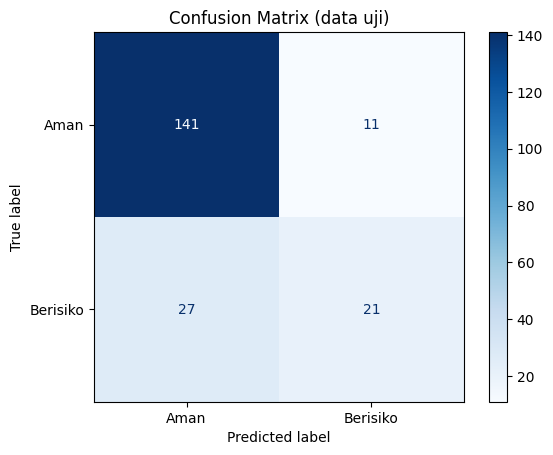

Contoh prediksi mahasiswa baru:


,ipk,kehadiran,sks_mengulang,rata_tugas,semester,prediksi
0,2.1,55,4,48,6,BERISIKO
1,3.6,95,0,88,6,Aman


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Aman", "Berisiko"]).plot(cmap="Blues")
plt.title("Confusion Matrix (data uji)")
plt.show()

print("Contoh prediksi mahasiswa baru:")
baru = pd.DataFrame([{"ipk": 2.1, "kehadiran": 55, "sks_mengulang": 4, "rata_tugas": 48, "semester": 6},
                     {"ipk": 3.6, "kehadiran": 95, "sks_mengulang": 0, "rata_tugas": 88, "semester": 6}])
baru["prediksi"] = np.where(model.predict(baru) == 1, "BERISIKO", "Aman")
baru

In [ ]:
#5. Interpretasi: cek generalisasi (overfitting?)

In [ ]:
skor_latih = f1_score(y_train, model.predict(X_train))
skor_uji   = f1_score(y_test,  y_pred)
print(f"F1 data latih: {skor_latih:.3f}")
print(f"F1 data uji  : {skor_uji:.3f}")
print(f"Selisih      : {skor_latih - skor_uji:.3f}")

F1 data latih: 0.659
F1 data uji  : 0.525
Selisih      : 0.134
